
# 2D Gaussian Random Field from a Power-Law Power Spectrum

This notebook:

1. **Generates** a 2D Gaussian random field on an $N \times N$ grid whose power
   spectrum follows a power law $P(k) = A\,k^n$.
2. **Visualizes** the field as a heatmap.
3. **Extracts** the power spectrum back out of the generated field (by
   Fourier-transforming it and azimuthally averaging $|\delta_k|^2$ in bins
   of $|k|$) and compares it to the input $P(k)$.
4. **Smooths** the field with a top-hat filter of radius $R$ and visualizes
   the result.

Each of these steps lives in its own section with its own code cell(s), so
you can tweak parameters and re-run individual pieces without recomputing
everything.


## 0. Imports and global parameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1

plt.rcParams['figure.dpi'] = 110


In [2]:
# ----------------------------- Parameters -----------------------------
N     = 1024        # grid points per side (N x N field)
L     = 100.0       # physical size of the box (box side length, arbitrary units)
A     = 1.0e4        # amplitude of the power spectrum P(k) = A * k^n
n     = 0.965         # spectral index (slope of the power law)
Rf    = 0.5         # smoothing scale for the density field
SEED  = None            # RNG seed, set to None for a different realization each run
# ------------------------------------------------------------------------



## Generating the Gaussian random field

The idea:

1. Draw a real white-noise field $w(\mathbf{x})$ (i.i.d. Gaussian pixels).
2. Fourier-transform it: since $w(\mathbf{x})$ is real, $\hat w(\mathbf{k})$ is
   automatically Hermitian-symmetric ($\hat w(-\mathbf{k}) = \hat w(\mathbf{k})^*$),
   which guarantees a real field after the inverse transform later.
3. Build the wavevector grid $\mathbf{k} = (k_x, k_y)$ and the isotropic
   power law $P(k) = A\,|\mathbf{k}|^{\,n}$ (with $P(0)=0$, i.e. zero mean field).
4. Multiply: $\hat\delta(\mathbf{k}) = \hat w(\mathbf{k})\,\sqrt{P(k)}$.
   Because $\sqrt{P(k)}$ is real and depends only on $|\mathbf{k}|$, the
   Hermitian symmetry (and hence the reality of the field) is preserved.
5. Inverse Fourier transform to get the real-space Gaussian random field
   $\delta(\mathbf{x})$.

With this convention the discrete estimator used later in Section 3,
$\widehat{P}(k) = |\mathrm{FFT}[\delta]|^2 / N^2$, recovers exactly the
input $P(k)$ on average, so generation and measurement are self-consistent.


In [3]:
def wavevector_grid(N, L):
    """Return kx, ky (2D meshgrids) and kgrid = |k| for an N x N box of side L."""
    d = L / N
    k1d = 2 * np.pi * np.fft.fftfreq(N, d=d)
    kx, ky = np.meshgrid(k1d, k1d, indexing='ij')
    kgrid = np.sqrt(kx**2 + ky**2)
    return kx, ky, kgrid


def power_law_Pk(kgrid, A, n):
    """Isotropic power-law power spectrum P(k) = A * k^n, with P(k=0) = 0."""
    Pk = np.zeros_like(kgrid)
    mask = kgrid > 0
    Pk[mask] = A * kgrid[mask] ** n * np.exp(-(kgrid[mask] * Rf) ** 2)  # optional Gaussian smoothing
    return Pk


def generate_gaussian_random_field(N, L, A, n, seed=None):
    """
    Generate a 2D Gaussian random field on an N x N grid with power
    spectrum P(k) = A * k^n.

    Parameters
    ----------
    N : int          grid points per side
    L : float        physical box size
    A : float        power-spectrum amplitude
    n : float        power-spectrum spectral index
    seed : int/None  RNG seed

    Returns
    -------
    field : (N, N) ndarray   real-space Gaussian random field
    kx, ky, kgrid : ndarrays wavevector grids (useful downstream)
    """
    rng = np.random.default_rng(seed)

    # 1-2. real white noise -> Hermitian-symmetric Fourier field
    white_noise = rng.normal(0.0, 1.0, size=(N, N))
    noise_k = np.fft.fft2(white_noise)

    # 3. wavevector grid and target power spectrum
    kx, ky, kgrid = wavevector_grid(N, L)
    Pk = power_law_Pk(kgrid, A, n)

    # 4. impose the power spectrum
    field_k = noise_k * np.sqrt(Pk)
    field_k[0, 0] = 0.0  # zero mean

    # 5. back to real space (imaginary part is numerical noise, ~1e-14)
    field = np.fft.ifft2(field_k).real

    return field, kx, ky, kgrid


field, kx, ky, kgrid = generate_gaussian_random_field(N, L, A, n, seed=SEED)

print(f"Field shape: {field.shape}")
print(f"Field mean:  {field.mean():.3e}  (should be ~0)")
print(f"Field std:   {field.std():.3e}")


Field shape: (1024, 1024)
Field mean:  5.204e-18  (should be ~0)
Field std:   7.277e+00


## Visualizing the field as a heatmap

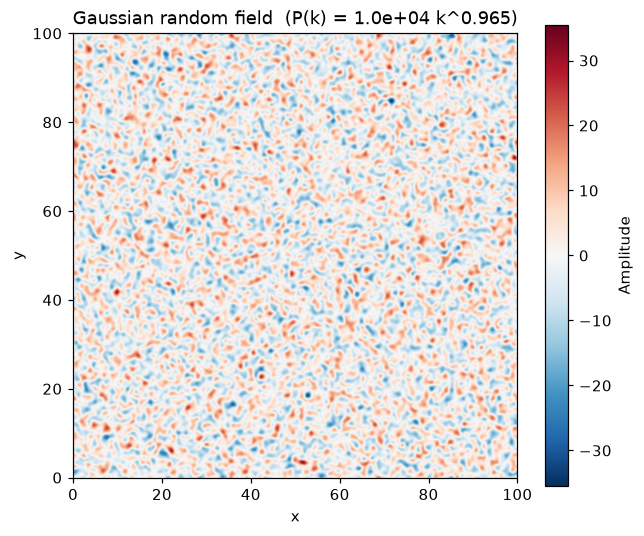

In [4]:
from matplotlib.colors import SymLogNorm

def plot_heatmap(field, L, title="Field", ax=None, cmap='RdBu_r',
                  scale='linear', linthresh=None):
    """
    Plot a real-space field as a heatmap with a colorbar.

    Parameters
    ----------
    scale : 'linear' or 'log'
        'log' uses a *symmetric* log-scale colormap (SymLogNorm), since a
        Gaussian random field has both positive and negative values and a
        plain log scale is undefined for negative numbers.
    linthresh : float or None
        Half-width of the linear region around zero (same units as the
        field), used only when scale='log'. |field| below this threshold
        is shown on a linear scale; above it, on a log scale. Defaults to
        1% of the field's peak amplitude.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    vmax = np.abs(field).max()

    if scale == 'log':
        if linthresh is None:
            linthresh = 0.01 * vmax
        norm = SymLogNorm(linthresh=linthresh, vmin=-vmax, vmax=vmax, base=10)
        im = ax.imshow(field, extent=[0, L, 0, L], origin='lower',
                        cmap=cmap, norm=norm)
        cbar_label = 'Amplitude (symlog scale)'
    else:
        im = ax.imshow(field, extent=[0, L, 0, L], origin='lower',
                        cmap=cmap, vmin=-vmax, vmax=vmax)
        cbar_label = 'Amplitude'

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(title)
    return ax


plot_heatmap(field, L, title=f"Gaussian random field  (P(k) = {A:.1e} k^{n})")
plt.tight_layout()
plt.show()


**Log color scale.** Since the field oscillates around zero, a plain `LogNorm` can't be used (log of a negative number is undefined). `SymLogNorm` instead applies a log scale for values with |amplitude| > `linthresh`, and a linear scale close to zero, so sign is preserved while large excursions get compressed logarithmically. Smaller `linthresh` means more of the map is log-scaled.

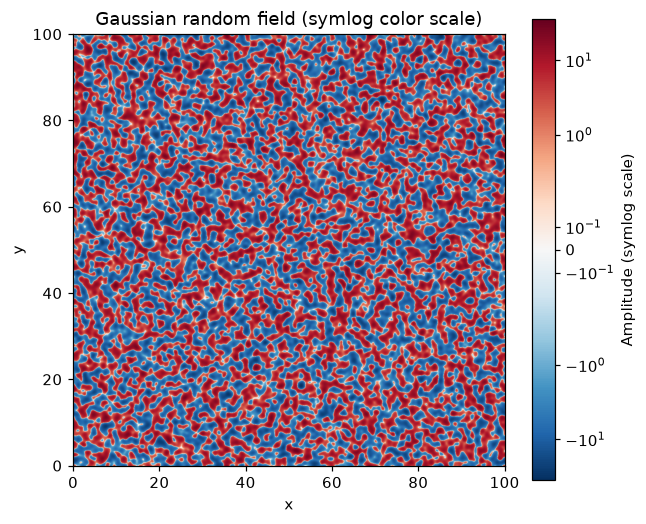

In [5]:
plot_heatmap(field, L, title="Gaussian random field (symlog color scale)",
             scale='log', linthresh=field.std() * 0.05)
plt.tight_layout()
plt.show()



## Extracting the power spectrum from the field

We Fourier-transform the generated field, take $|\hat\delta(\mathbf{k})|^2$,
and azimuthally average it in radial bins of $|\mathbf{k}|$ to obtain an
isotropic estimate $\widehat P(k)$. This is then compared, on a log-log plot,
to the theoretical input $P(k) = A\,k^n$.

### Spectrum extraction parameters:
* Number of bins
* Lowest multiple of the minimum non-zero k to start the bins at. This avoids the first bin being dominated by the DC mode (k=0) and very low-k modes, which can be noisy and not representative of the power spectrum.

In [6]:
n_bins = 30
low_mult = 10

In [7]:
def compute_power_spectrum(field, L, n_bins=30, bin_type='linear'):
    """
    Estimate the isotropic power spectrum of a real-space field by
    azimuthally averaging |FFT(field)|^2 / N^2 in bins of |k|.

    Parameters
    ----------
    bin_type : 'linear' or 'log'
        'linear' bins are evenly spaced in k (few, noisy bins at low k,
        since low-k shells contain very few independent Fourier modes).
        'log' bins are evenly spaced in log(k), which matches the
        power-law nature of P(k) and avoids near-empty bins at low k.

    Returns
    -------
    k_centers : bin-center wavenumbers
    Pk_binned : azimuthally averaged power in each bin
    n_modes   : number of independent Fourier modes averaged in each bin
                (a direct measure of how noisy/reliable each point is)
    """
    N = field.shape[0]
    kx, ky, kgrid = wavevector_grid(N, L)

    field_k = np.fft.fft2(field)
    Pk_2d = np.abs(field_k) ** 2 / N**2   # consistent with the generation normalization

    k_flat = kgrid.ravel()
    Pk_flat = Pk_2d.ravel()

    kmin = k_flat[k_flat > 0].min()*10   # fundamental mode, k_min = 2*pi/L
    kmax = k_flat.max() / np.sqrt(2)               # Nyquist-limited, k_max ~ pi*N/L

    if bin_type == 'log':
        bin_edges = np.logspace(np.log10(kmin), np.log10(kmax), n_bins + 1)
    else:
        bin_edges = np.linspace(kmin, kmax, n_bins + 1)
    k_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    Pk_binned = np.full(n_bins, np.nan)
    n_modes = np.zeros(n_bins, dtype=int)
    for i in range(n_bins):
        sel = (k_flat >= bin_edges[i]) & (k_flat < bin_edges[i + 1])
        n_modes[i] = np.count_nonzero(sel)
        if n_modes[i] > 0:
            Pk_binned[i] = Pk_flat[sel].mean()

    valid = ~np.isnan(Pk_binned)
    return k_centers[valid], Pk_binned[valid], n_modes[valid]


k_est, Pk_est, n_modes_est = compute_power_spectrum(field, L, n_bins, bin_type='log')


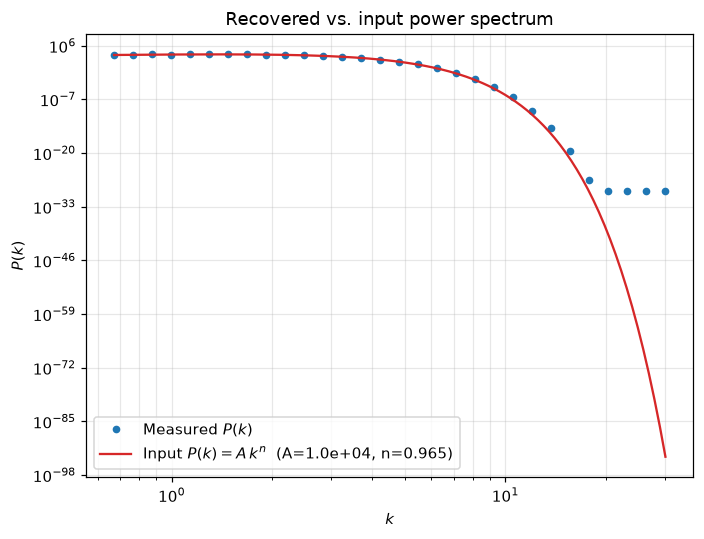

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 5))

ax.loglog(k_est, Pk_est, 'o', ms=4, color='tab:blue', label='Measured $P(k)$')

k_theory = np.logspace(np.log10(k_est.min()), np.log10(k_est.max()), 200)
ax.loglog(k_theory, A * k_theory**n * np.exp(-(k_theory * Rf) ** 2), '-', color='tab:red',
          label=r'Input $P(k) = A\,k^{n}$' + f'  (A={A:.1e}, n={n})')

ax.set_xlabel(r'$k$')
ax.set_ylabel(r'$P(k)$')
ax.set_title('Recovered vs. input power spectrum')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()


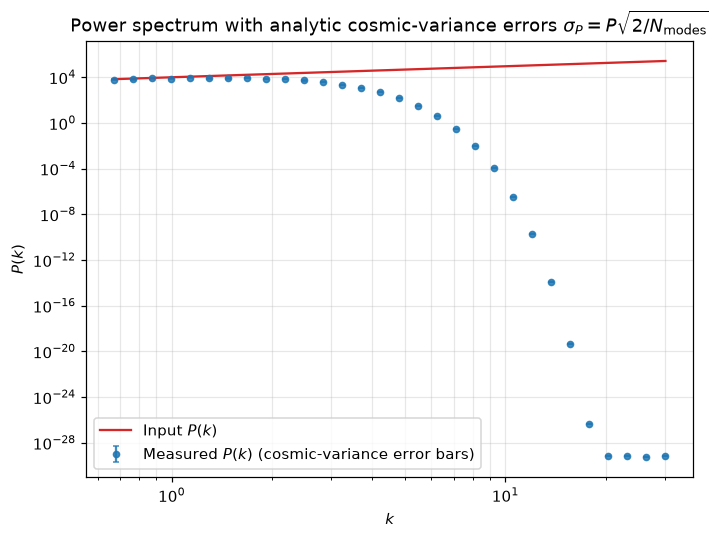

In [9]:
# Analytic cosmic-variance error bars from a single realization
sigma_Pk = Pk_est * np.sqrt(2.0 / n_modes_est)

fig, ax = plt.subplots(figsize=(6.5, 5))

ax.errorbar(k_est, Pk_est, yerr=sigma_Pk, fmt='o', ms=4, capsize=2,
            color='tab:blue', ecolor='tab:blue', alpha=0.85,
            label='Measured $P(k)$ (cosmic-variance error bars)')
ax.loglog(k_theory, A * k_theory**n, '-', color='tab:red', label='Input $P(k)$')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$k$')
ax.set_ylabel(r'$P(k)$')
ax.set_title(r'Power spectrum with analytic cosmic-variance errors $\sigma_P = P\sqrt{2/N_{\rm modes}}$')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

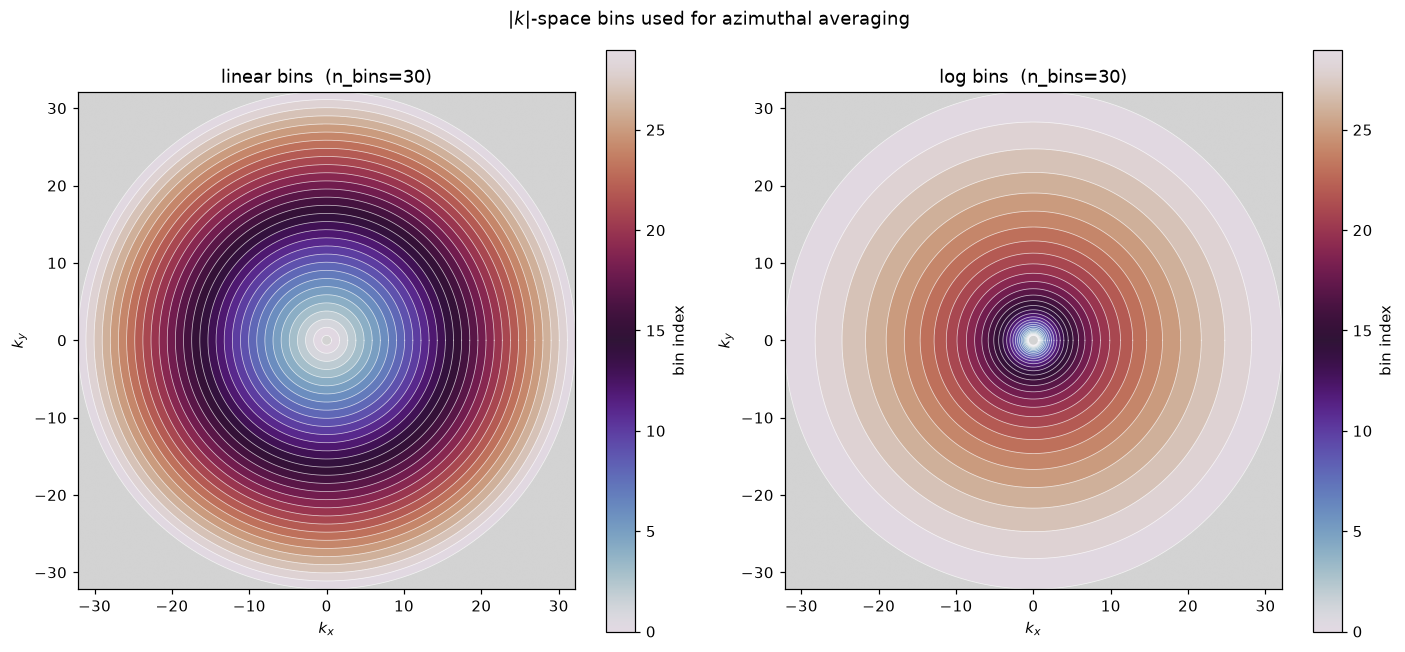

In [10]:
def plot_kspace_bins(N, L, n_bins=30, bin_type='linear', ax=None):
    """
    Color each Fourier mode (kx, ky) by the radial |k| bin it belongs to,
    exactly matching the binning used by compute_power_spectrum. Modes
    that fall outside any bin (the k=0 mode, or the very corner modes
    with |k| == k_max, which fail the strict '<' upper-bin-edge test)
    are shown in light gray.
    """
    kx, ky, kgrid = wavevector_grid(N, L)
    k_flat = kgrid.ravel()
    kmin = k_flat[k_flat > 0].min() * 10
    kmax = k_flat.max() / np.sqrt(2) 

    if bin_type == 'log':
        bin_edges = np.logspace(np.log10(kmin), np.log10(kmax), n_bins + 1)
    else:
        bin_edges = np.linspace(kmin, kmax, n_bins + 1)

    # np.digitize matches the [edge_i, edge_{i+1}) convention used in
    # compute_power_spectrum
    bin_idx = np.digitize(kgrid, bin_edges) - 1
    included = (bin_idx >= 0) & (bin_idx < n_bins)
    bin_map = np.where(included, bin_idx, np.nan)

    # fftshift so k=0 sits at the center of the plot (more intuitive)
    bin_map = np.fft.fftshift(bin_map)
    kx_s, ky_s = np.fft.fftshift(kx), np.fft.fftshift(ky)
    extent = [kx_s.min(), kx_s.max(), ky_s.min(), ky_s.max()]

    if ax is None:
        fig, ax = plt.subplots(figsize=(6.5, 6))

    cmap = plt.get_cmap('twilight').copy()
    cmap.set_bad('lightgray')
    im = ax.imshow(bin_map, extent=extent, origin='lower', cmap=cmap, vmin=0, vmax=n_bins - 1)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])

    theta = np.linspace(0, 2 * np.pi, 200)
    for edge in bin_edges:
        ax.plot(edge * np.cos(theta), edge * np.sin(theta),
                color='white', lw=0.5, alpha=0.7)

    ax.set_xlabel(r'$k_x$')
    ax.set_ylabel(r'$k_y$')
    ax.set_aspect('equal')
    ax.set_title(f"{bin_type} bins  (n_bins={n_bins})")
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('bin index')
    return ax


fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_kspace_bins(N, L, n_bins, bin_type='linear', ax=axes[0])
plot_kspace_bins(N, L, n_bins, bin_type='log', ax=axes[1])
fig.suptitle('$|k|$-space bins used for azimuthal averaging')
plt.tight_layout()
plt.show()


### Comments on binning choiches

On a periodic $N \times N$ grid of size $L$, the Fourier modes are
**discrete**, not continuous:

$$
k_x, k_y = \frac{2\pi}{L}\,\{-N/2,\dots,N/2-1\},
\qquad
k_{\min} = \frac{2\pi}{L}\ \text{(fundamental mode)},
\qquad
k_{\max} \approx \frac{\pi N}{L}\ \text{(Nyquist)}.
$$

When we azimuthally average $|\hat\delta(\mathbf{k})|^2$ in a shell at
radius $k$, the **number of independent modes in that shell grows
linearly with $k$** (shell area $\propto k\,dk$ in 2D). Near $k_{\min}$
a shell might contain only a handful of modes (as few as 4-8), so:

- the low-$k$ points are estimated from very few samples $\Rightarrow$
  **large statistical scatter** ("sample variance" / "cosmic variance"),
- with **linear** bins, the first bin can be nearly empty, giving you
  very few usable low-$k$ points at all — this is the "finite k" /
  sparse-looking start of the curve you're seeing.

This is a fundamental consequence of simulating a **finite, periodic**
box — it is not really about the choice of boundary condition itself.
Any finite box (periodic, or with Dirichlet/Neumann boundaries via a
sine/cosine transform) still only supports a discrete, finite set of
low-$k$ modes; periodic boundaries (implicit in using the FFT) are
already the standard and most convenient choice, and changing the
boundary condition type would not add more independent large-scale modes.

**What actually helps:**

1. **Log-spaced bins instead of linear bins.** This doesn't create new
   modes, but it stops wasting bins on the (mode-poor) low-$k$ end and
   groups them more sensibly — very effective for power laws spanning
   decades in $k$.
2. **A bigger box (larger $L$ at fixed resolution).** Since
   $k_{\min}=2\pi/L$, increasing $L$ pushes $k_{\min}$ down and gives you
   *more* modes at low $k$ (more, finer shells before you run out of
   large-scale structure). The trade-off: for fixed $N$, a bigger $L$
   means coarser real-space resolution (larger pixel size $d=L/N$); to
   keep the same resolution you also need to increase $N$.
3. **Averaging over multiple independent realizations** (ensemble
   averaging). This is the standard fix for the *scatter*, even though
   it doesn't add new modes for a single box: generate several GRFs with
   the same $P(k)$, measure $P(k)$ for each, and average — the low-$k$
   error bars shrink like $1/\sqrt{N_{\rm realizations}}$.

The next cells demonstrate options 1 and 3.


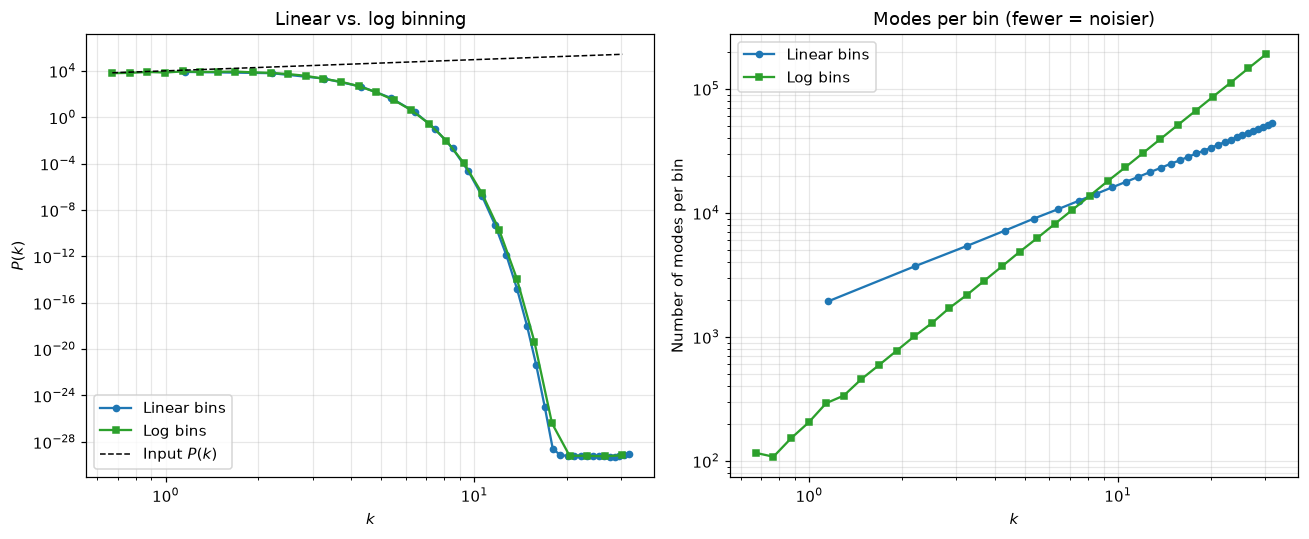

In [11]:
# Option 1: log-spaced bins vs. linear bins, same single realization
k_lin, Pk_lin, nmodes_lin = compute_power_spectrum(field, L, n_bins=30, bin_type='linear')
k_log, Pk_log, nmodes_log = compute_power_spectrum(field, L, n_bins=30, bin_type='log')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].loglog(k_lin, Pk_lin, 'o-', ms=4, color='tab:blue', label='Linear bins')
axes[0].loglog(k_log, Pk_log, 's-', ms=4, color='tab:green', label='Log bins')
axes[0].loglog(k_theory, A * k_theory**n, 'k--', lw=1, label='Input $P(k)$')
axes[0].set_xlabel(r'$k$'); axes[0].set_ylabel(r'$P(k)$')
axes[0].set_title('Linear vs. log binning')
axes[0].legend(); axes[0].grid(True, which='both', alpha=0.3)

axes[1].loglog(k_lin, nmodes_lin, 'o-', ms=4, color='tab:blue', label='Linear bins')
axes[1].loglog(k_log, nmodes_log, 's-', ms=4, color='tab:green', label='Log bins')
axes[1].set_xlabel(r'$k$'); axes[1].set_ylabel('Number of modes per bin')
axes[1].set_title('Modes per bin (fewer = noisier)')
axes[1].legend(); axes[1].grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()


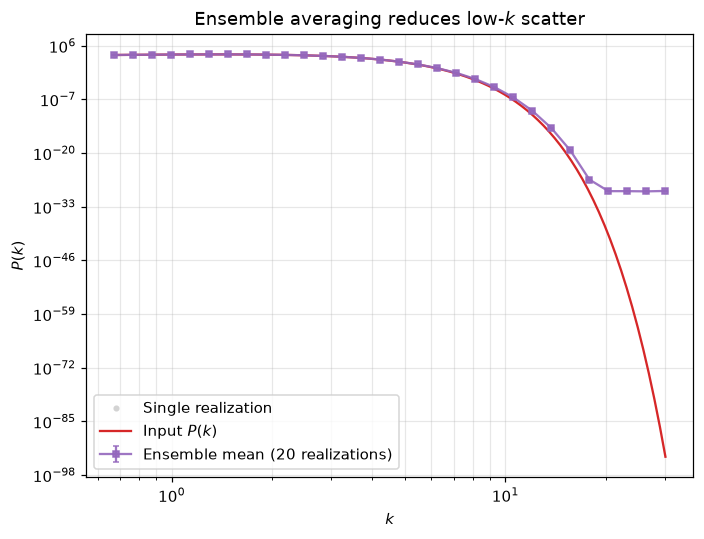

In [17]:
# Option 3: ensemble averaging over independent realizations
def ensemble_power_spectrum(N, L, A, n, n_realizations=20, n_bins=30,
                             bin_type='log', seed=None):
    """
    Generate several independent GRF realizations with the same P(k) and
    return the mean and standard deviation of the measured power spectrum
    across realizations (reduces sample variance, especially at low k).
    """
    rng = np.random.default_rng(seed)
    Pk_realizations = []
    k_ref = None
    for _ in range(n_realizations):
        f, _, _, _ = generate_gaussian_random_field(
            N, L, A, n, seed=rng.integers(0, 2**31 - 1))
        k_i, Pk_i, _ = compute_power_spectrum(f, L, n_bins=n_bins, bin_type=bin_type)
        if k_ref is None:
            k_ref = k_i
        Pk_realizations.append(Pk_i)

    Pk_realizations = np.array(Pk_realizations)
    Pk_mean = Pk_realizations.mean(axis=0)
    Pk_std = Pk_realizations.std(axis=0)
    return k_ref, Pk_mean, Pk_std


k_ens, Pk_ens_mean, Pk_ens_std = ensemble_power_spectrum(
    N, L, A, n, n_realizations=40, n_bins=30, bin_type='log', seed=SEED)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.loglog(k_est, Pk_est, 'o', ms=3, color='lightgray', label='Single realization')
ax.errorbar(k_ens, Pk_ens_mean, yerr=Pk_ens_std, fmt='s-', ms=4,
            color='tab:purple', ecolor='tab:purple', alpha=0.9, capsize=2,
            label='Ensemble mean (20 realizations)')
ax.loglog(k_theory, A * k_theory**n * np.exp(-(k_theory * Rf) ** 2), '-', color='tab:red', label='Input $P(k)$')
ax.set_xlabel(r'$k$'); ax.set_ylabel(r'$P(k)$')
ax.set_title('Ensemble averaging reduces low-$k$ scatter')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()
